# Basket: Bilingual Support Ticket Assistant

This project classifies Arabic and English support messages, retrieves similar cases, and prepares replies supported by store policies. **Basket is a fictional online store.**

This project compares TF-IDF, multilingual embeddings, and encoder fine-tuning on the same test set and includes a bilingual Gradio demo.

Use a **T4 GPU** in Google Colab to run the full training experiment.

#### Step 1: Load Project Files and Install Dependencies

The project files are loaded from GitHub. The required libraries support data processing, model training, retrieval, evaluation, and the Gradio interface.

In [51]:
from pathlib import Path
import os
import subprocess
import sys

REPO_URL = "https://github.com/layan54/bilingual-support-ticket-assistant.git"
PROJECT = (
    Path("/content/bilingual-support-ticket-assistant")
    if Path("/content").exists()
    else Path.cwd()
)
if not (PROJECT / "config.json").exists():
    if PROJECT.exists() and any(PROJECT.iterdir()):
        raise RuntimeError(
            "The project directory exists but is incomplete. Use a fresh runtime."
        )
    subprocess.run(["git", "clone", REPO_URL, str(PROJECT)], check=True)
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--only-binary=pandas",
        "-r",
        "requirements.txt",
    ],
    check=True,
)
print("Project loaded:", PROJECT.name)


Project loaded: bilingual-support-ticket-assistant


#### Step 2: Set Up the Environment

A fixed random seed makes the experiments more reproducible. Configuration values define the six intent classes, model choices, and training settings.

In [52]:
import gc
import json
import random
import time
import re
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = PROJECT
DATA = ROOT / "data"
ART = ROOT / "artifacts"
EVAL = ROOT / "evaluation"
ART.mkdir(exist_ok=True)
EVAL.mkdir(exist_ok=True)
CONFIG = json.loads((ROOT / "config.json").read_text())
LABELS = CONFIG["labels"]
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if not torch.cuda.is_available():
    raise RuntimeError(
        "Select Runtime > Change runtime type > T4 GPU for the full experiment."
    )
torch.cuda.manual_seed_all(CONFIG["seed"])
print("GPU:", torch.cuda.get_device_name(0))
print("Seed:", CONFIG["seed"])


GPU: Tesla T4
Seed: 42


#### Step 3: Load and Explore the Data

English support messages come from Bitext. Arabic training and validation examples are synthetic, with a separate Arabic evaluation set. A bilingual policy collection supplies the evidence for replies. Detailed sources are listed in the README.

This step examines class and language distributions and verifies that the training, validation, test, and historical-case splits do not share ticket IDs or exact normalized messages.

In [53]:
def canonical(text):
    text = re.sub("\\{\\{.*?\\}\\}", " ID ", str(text))
    text = re.sub("\\b[A-Za-z]*[-_]?\\d[\\w-]*\\b", " ID ", text)
    return re.sub("\\W+", " ", text.lower()).strip()


def load(split):
    path = DATA / "prepared" / f"{split}.csv"
    if not path.exists():
        raise FileNotFoundError("Run the data preparation cell first.")
    return pd.read_csv(path).fillna({"response": ""})


splits = {name: load(name) for name in ["train", "val", "test", "history"]}
train, val, test, history = [splits[name] for name in ["train", "val", "test", "history"]]
counts = (
    pd.DataFrame({name: frame.groupby("lang").size() for name, frame in splits.items()})
    .fillna(0)
    .astype(int)
)
display(counts)
display(pd.crosstab(train.intent, train.lang))
display(train[["text", "intent", "lang"]].sample(6, random_state=CONFIG["seed"]))
for i, (left, a) in enumerate(splits.items()):
    for right, b in list(splits.items())[i + 1 :]:
        assert not set(a.ticket_id) & set(b.ticket_id), (left, right, "shared IDs")
        assert not set(a.text.map(canonical)) & set(b.text.map(canonical)), (
            left,
            right,
            "shared text",
        )
print("Split integrity checks passed.")


,train,val,test,history
lang,,,,
ar,120,36,24,0
en,1200,240,240,1800


lang,ar,en
intent,,
cancel_order,20,200
change_shipping_address,20,200
get_refund,20,200
payment_issue,20,200
track_order,20,200
track_refund,20,200


,text,intent,lang
678,i dont know how to inform of paymentissues,payment_issue,en
693,how can I inform of a trouble with payments?,payment_issue,en
610,can uhelp me to solve a problem with online pa...,payment_issue,en
49,I want help checking order {{Order Number}} cu...,track_order,en
1291,أبي نموذج طلب استرداد,get_refund,ar
486,need assistance trying to change the address,change_shipping_address,en


Split integrity checks passed.


**Data overview:** The dataset contains 1,320 training messages, 276 validation messages, 264 test messages, and 1,800 historical cases. The Arabic test set contains 24 messages, which limits how broadly its results can be generalized. Exact deduplication does not remove all template or semantic similarity.

#### Step 4: Define Evaluation Helpers

All classifiers save predictions in the same format. Confidence thresholds are chosen using validation data, while test labels are used only for evaluation.

In [54]:
def seed_all():
    random.seed(CONFIG["seed"])
    np.random.seed(CONFIG["seed"])
    import torch

    torch.manual_seed(CONFIG["seed"])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(CONFIG["seed"])


def tune_threshold(y, probs, classes):
    conf = probs.max(1)
    correct = np.asarray(classes)[probs.argmax(1)] == np.asarray(y)
    choices = []
    for tau in np.linspace(0, 0.99, 100):
        keep = conf >= tau
        if keep.sum() >= 20 and correct[keep].mean() >= 0.9:
            choices.append((keep.mean(), float(tau)))
    return max(choices)[1] if choices else 1.01


def save_predictions(name, df, probs, classes, latency_ms=None):
    result = (
        df[["ticket_id", "text", "intent", "lang", "dialect", "source"]]
        .rename(columns={"intent": "y_true"})
        .copy()
    )
    result["y_pred"] = np.asarray(classes)[probs.argmax(1)]
    result["confidence"] = probs.max(1)
    result["model"] = name
    if latency_ms is not None:
        result["latency_ms"] = latency_ms
    result.to_csv(EVAL / f"{name}_predictions.csv", index=False)
    return result


#### Step 5: Train the TF-IDF Baseline

The TF-IDF baseline was trained on English support messages.

In [55]:
train, val, test = load("train"), load("val"), load("test")
model = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True),
    LogisticRegression(C=4, max_iter=2000, random_state=CONFIG["seed"]),
)
en = train[train.lang == "en"]
model.fit(en.text, en.intent)
probs = model.predict_proba(test.text)
tau = tune_threshold(val.intent, model.predict_proba(val.text), model.classes_)
joblib.dump(model, ART / "tfidf.joblib")
save_predictions("tfidf_en", test, probs, model.classes_)
(ART / "tfidf_meta.json").write_text(
    json.dumps(
        {
            "tau": tau,
            "training": "English-only",
            "type": "TF-IDF char ngrams + LogisticRegression",
        }
    )
)
print("TF-IDF English-only baseline saved.")


TF-IDF English-only baseline saved.


#### Step 6: Train the Embedding-Based Classifiers

Two classifiers were trained using frozen multilingual e5 embeddings: one with English-only data and one with bilingual data.

In [56]:
seed_all()
from sentence_transformers import SentenceTransformer
import torch

train, val, test = load("train"), load("val"), load("test")
encoder = SentenceTransformer(
    CONFIG["embedding_model"],
    revision=CONFIG.get("model_revisions", {}).get("embedding_model"),
    device="cuda" if torch.cuda.is_available() else "cpu",
)
X = {}
for name, df in [("train", train), ("val", val), ("test", test)]:
    X[name] = encoder.encode(
        ["query: " + t for t in df.text],
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
metadata = {}
for name, mask in [
    ("e5_en", train.lang.eq("en").to_numpy()),
    ("e5_bilingual", np.ones(len(train), dtype=bool)),
]:
    model = LogisticRegression(C=10, max_iter=3000, random_state=CONFIG["seed"]).fit(
        X["train"][mask], train.intent.to_numpy()[mask]
    )
    tau = tune_threshold(val.intent, model.predict_proba(X["val"]), model.classes_)
    p = model.predict_proba(X["test"])
    joblib.dump(model, ART / f"{name}.joblib")
    save_predictions(name, test, p, model.classes_)
    metadata[name] = {
        "tau": tau,
        "n_train": int(mask.sum()),
        "embedding_model": CONFIG["embedding_model"],
    }
    # Warm-up followed by wall-clock, single-request embedding + classification latency.
    for t in test.text.head(3):
        model.predict_proba(encoder.encode(["query: " + t], normalize_embeddings=True))
    times = []
    for t in test.text.head(40):
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        model.predict_proba(encoder.encode(["query: " + t], normalize_embeddings=True))
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times.append((time.perf_counter() - start) * 1000)
    metadata[name]["p95_ms"] = float(np.percentile(times, 95))
np.savez_compressed(ART / "e5_features.npz", **X)
# Semantic proximity is a diagnostic, not proof of duplication.
sim = X["test"] @ X["train"].T
best = sim.argmax(1)
audit = pd.DataFrame(
    {
        "ticket_id": test.ticket_id,
        "closest_train_id": train.ticket_id.to_numpy()[best],
        "max_cosine": sim.max(1),
        "lang": test.lang,
    }
)
audit.to_csv(EVAL / "semantic_overlap_audit.csv", index=False)
(ART / "e5_meta.json").write_text(json.dumps(metadata, indent=2))
del encoder
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("English-only and bilingual e5 baselines saved.")


Batches:   0%|          | 0/21 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

English-only and bilingual e5 baselines saved.


#### Step 7: Fine-Tune the Encoder

Multilingual DistilBERT is fine-tuned on the bilingual training split. Early stopping uses validation macro-F1. The serving classifier is selected by comparing validation macro-F1 across the embedding-based and fine-tuned models.

In [57]:
seed_all()
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "Select Runtime > Change runtime type > T4 GPU before running fine-tuning."
    )
train, val, test = load("train"), load("val"), load("test")
label2id = {x: i for i, x in enumerate(LABELS)}
id2label = {i: x for x, i in label2id.items()}
tok = AutoTokenizer.from_pretrained(
    CONFIG["encoder_model"], revision=CONFIG.get("model_revisions", {}).get("encoder_model")
)
# Length selection uses training text only; no test-dependent hyperparameters.
lens = [len(x) for x in tok(train.text.tolist(), truncation=False)["input_ids"]]
maxlen = int(
    min(CONFIG["max_length_cap"], max(16, 8 * np.ceil(np.percentile(lens, 99) / 8)))
)


def dataset(df):
    ds = Dataset.from_dict(
        {"text": df.text.tolist(), "label": df.intent.map(label2id).tolist()}
    )
    return ds.map(
        lambda b: tok(b["text"], truncation=True, max_length=maxlen),
        batched=True,
        remove_columns=["text"],
    )


tr, va, te = map(dataset, [train, val, test])
model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["encoder_model"],
    revision=CONFIG.get("model_revisions", {}).get("encoder_model"),
    num_labels=len(LABELS),
    label2id=label2id,
    id2label=id2label,
)


def metrics(p):
    pred = p.predictions.argmax(-1)
    return {
        "macro_f1": f1_score(
            p.label_ids,
            pred,
            labels=list(range(len(LABELS))),
            average="macro",
            zero_division=0,
        ),
        "accuracy": accuracy_score(p.label_ids, pred),
    }


args = TrainingArguments(
    output_dir=str(ART / "checkpoints"),
    learning_rate=CONFIG["learning_rate"],
    num_train_epochs=CONFIG["epochs"],
    per_device_train_batch_size=CONFIG["train_batch_size"],
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    warmup_ratio=0.1,
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    report_to="none",
    seed=CONFIG["seed"],
)
trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tr,
    eval_dataset=va,
    processing_class=tok,
    data_collator=DataCollatorWithPadding(tok),
    compute_metrics=metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer.train()
pv = torch.softmax(torch.tensor(trainer.predict(va).predictions), dim=-1).numpy()
tau = tune_threshold(val.intent, pv, LABELS)
pt = torch.softmax(torch.tensor(trainer.predict(te).predictions), dim=-1).numpy()
save_predictions("encoder_finetuned", test, pt, LABELS)
dest = ART / "encoder"
trainer.save_model(str(dest))
tok.save_pretrained(str(dest))
pd.DataFrame(trainer.state.log_history).to_csv(EVAL / "training_log.csv", index=False)
# Select serving model on validation only, never on final test scores.
allscores = {
    "encoder_finetuned": f1_score(
        val.intent,
        np.array(LABELS)[pv.argmax(1)],
        labels=LABELS,
        average="macro",
        zero_division=0,
    )
}
features = np.load(ART / "e5_features.npz")
for name in ["e5_en", "e5_bilingual"]:
    lr = joblib.load(ART / f"{name}.joblib")
    allscores[name] = f1_score(
        val.intent,
        lr.predict(features["val"]),
        labels=LABELS,
        average="macro",
        zero_division=0,
    )
best = max(allscores, key=allscores.get)
meta = {
    "tau": tau,
    "max_length": maxlen,
    "model": CONFIG["encoder_model"],
    "validation_macro_f1": allscores,
    "serving_model": best,
    "n_train": len(train),
}
(ART / "encoder_meta.json").write_text(json.dumps(meta, indent=2))
(EVAL / "validation_selection.json").write_text(json.dumps(meta, indent=2))
print("Best serving classifier on validation:", best, allscores)
del trainer, model
gc.collect()
torch.cuda.empty_cache()


Map:   0%|          | 0/1320 [00:00<?, ? examples/s]

Map:   0%|          | 0/276 [00:00<?, ? examples/s]

Map:   0%|          | 0/264 [00:00<?, ? examples/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,1.144100,0.427340,0.874153,0.869565
2,0.217400,0.201379,0.941951,0.942029
3,0.089500,0.197365,0.931609,0.931159
4,0.050000,0.132003,0.949110,0.949275


Best serving classifier on validation: e5_bilingual {'encoder_finetuned': 0.9491102449589857, 'e5_en': 0.9493991328511568, 'e5_bilingual': 0.971050854501065}


**Results:** Bilingual e5 was selected as the serving classifier with a validation macro-F1 of 0.9711.

#### Step 8: Compare Test Results

All four systems are evaluated on identical test IDs. Stratified bootstrap intervals show uncertainty in macro-F1, and confusion matrices reveal which intents are confused.

            model slice   n  accuracy  macro_f1  ci95_low  ci95_high
         tfidf_en   all 264    0.9242    0.9295    0.9028     0.9563
         tfidf_en    en 240    1.0000    1.0000    1.0000     1.0000
         tfidf_en    ar  24    0.1667    0.0476    0.0476     0.0476
            e5_en   all 264    0.9697    0.9697    0.9467     0.9886
            e5_en    en 240    0.9958    0.9958    0.9875     1.0000
            e5_en    ar  24    0.7083    0.6731    0.4978     0.8243
     e5_bilingual   all 264    0.9886    0.9886    0.9735     1.0000
     e5_bilingual    en 240    0.9958    0.9958    0.9875     1.0000
     e5_bilingual    ar  24    0.9167    0.9111    0.7778     1.0000
encoder_finetuned   all 264    0.9811    0.9811    0.9620     0.9944
encoder_finetuned    en 240    0.9917    0.9917    0.9793     1.0000
encoder_finetuned    ar  24    0.8750    0.8737    0.7307     0.9577
{
  "evaluation_status": "classifier comparison complete; inspect retrieval and reply reports too",
  "

,model,slice,n,accuracy,macro_f1,ci95_low,ci95_high
0,tfidf_en,all,264,0.924242,0.929453,0.902840,0.956307
1,tfidf_en,en,240,1.000000,1.000000,1.000000,1.000000
2,tfidf_en,ar,24,0.166667,0.047619,0.047619,0.047619
3,e5_en,all,264,0.969697,0.969673,0.946713,0.988608
4,e5_en,en,240,0.995833,0.995833,0.987482,1.000000
5,e5_en,ar,24,0.708333,0.673148,0.497802,0.824289
6,e5_bilingual,all,264,0.988636,0.988633,0.973461,1.000000
7,e5_bilingual,en,240,0.995833,0.995833,0.987482,1.000000
8,e5_bilingual,ar,24,0.916667,0.911111,0.777778,1.000000
9,encoder_finetuned,all,264,0.981061,0.981058,0.962028,0.994432


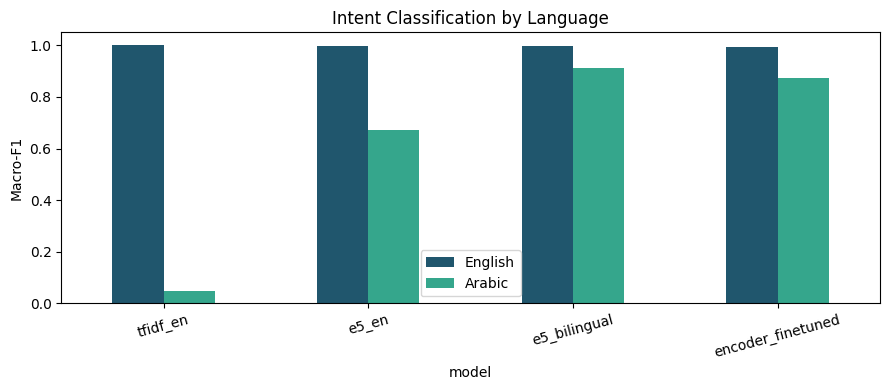

In [67]:
def score(df):
    return f1_score(df.y_true, df.y_pred, labels=LABELS, average="macro", zero_division=0)


def ci(df, n=300):
    rng = np.random.default_rng(CONFIG["seed"])
    scores = []
    groups = [g for _, g in df.groupby("y_true")]
    for _ in range(n):
        sample = pd.concat([g.iloc[rng.integers(0, len(g), len(g))] for g in groups])
        scores.append(score(sample))
    return np.percentile(scores, [2.5, 97.5]).tolist()


def report():
    files = [
        EVAL / f"{name}_predictions.csv"
        for name in ["tfidf_en", "e5_en", "e5_bilingual", "encoder_finetuned"]
        if (EVAL / f"{name}_predictions.csv").exists()
    ]
    frames = {p.name.removesuffix("_predictions.csv"): pd.read_csv(p) for p in files}
    if not frames:
        raise RuntimeError("No measured predictions. Run training first.")
    expected = set(load("test").ticket_id)
    rows = []
    errors = []
    for name, df in frames.items():
        if set(df.ticket_id) != expected or df.ticket_id.duplicated().any():
            raise ValueError(f"{name}: not the same complete held-out test set")
        gold = load("test").set_index("ticket_id").intent
        if not df.y_true.equals(df.ticket_id.map(gold).rename("y_true")):
            raise ValueError(f"{name}: gold labels mismatch")
        for lang in ["all", "en", "ar"]:
            g = df if lang == "all" else df[df.lang == lang]
            lo, hi = ci(g)
            rows.append(
                {
                    "model": name,
                    "slice": lang,
                    "n": len(g),
                    "accuracy": accuracy_score(g.y_true, g.y_pred),
                    "macro_f1": score(g),
                    "ci95_low": lo,
                    "ci95_high": hi,
                }
            )
        cm = confusion_matrix(df.y_true, df.y_pred, labels=LABELS)
        pd.DataFrame(cm, index=LABELS, columns=LABELS).to_csv(
            EVAL / f"{name}_confusion.csv"
        )
        err = df[df.y_true != df.y_pred].copy()
        err["cause"] = np.where(
            (err.lang == "ar") & name.endswith("_en"),
            "coverage: English-only training",
            "model error: incorrect intent",
        )
        err["diagnosis_status"] = np.where(
            (err.lang == "ar") & name.endswith("_en"),
            "supported training-language gap; per-example review still recommended",
            "provisional; review ambiguity and gold label",
        )
        err["stage"] = "classification"
        errors.append(err)
    table = pd.DataFrame(rows)
    table.to_csv(EVAL / "classification_metrics.csv", index=False)
    failures = pd.concat(errors, ignore_index=True)
    failures.to_csv(EVAL / "all_categorized_failures.csv", index=False)
    first = failures.drop_duplicates("ticket_id").head(20)
    first.to_csv(EVAL / "error_analysis.csv", index=False)
    summary = {
        "evaluation_status": (
            "partial"
            if "encoder_finetuned" not in frames
            else "classifier comparison complete; inspect retrieval and reply reports too"
        ),
        "models": list(frames),
        "test_size": len(expected),
        "distinct_failed_messages": len(failures.ticket_id.unique()),
        "reviewed_failure_table_size": len(first),
        "at_least_10_observed_failures": len(first) >= 10,
        "note": "Cause tags are diagnostic suggestions unless a separate manual review file confirms them. No fabricated failures.",
    }
    (EVAL / "status.json").write_text(json.dumps(summary, indent=2))
    print(table.round(4).to_string(index=False))
    print(json.dumps(summary, indent=2))
    return table


results = report()
display(results)
comparison = results.pivot(index="model", columns="slice", values="macro_f1").loc[
    ["tfidf_en", "e5_en", "e5_bilingual", "encoder_finetuned"]
]
comparison[["en", "ar"]].plot(kind="bar", figsize=(9, 4), color=["#20566d", "#35a68c"])
plt.title("Intent Classification by Language")
plt.ylabel("Macro-F1")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(["English", "Arabic"])
plt.tight_layout()
plt.show()


**Results:**

| System | English macro-F1 | Arabic macro-F1 | Overall macro-F1 |
|---|---:|---:|---:|
| TF-IDF | 1.0000 | 0.0476 | 0.9295 |
| English-only e5 | 0.9958 | 0.6731 | 0.9697 |
| Bilingual e5 | 0.9958 | 0.9111 | 0.9886 |
| Fine-tuned DistilBERT | 0.9917 | 0.8737 | 0.9811 |

Bilingual e5 achieved the highest overall test macro-F1 of 0.9886. Fine-tuned DistilBERT did not outperform the bilingual frozen-embedding classifier in this experiment. The Arabic 95% macro-F1 interval for bilingual e5 is **[0.7778, 1.0000]**, overlapping the fine-tuned encoder interval. The small Arabic test set limits how broadly this comparison can be generalized.

#### Step 9: Analyze Classification Errors

Incorrect predictions and their error categories are examined. The manually checked table includes ten observed baseline failures; suggested diagnoses in the larger table remain provisional.

,ticket_id,text,expected,predicted,stage,cause,evidence,review_status
0,course-ar-test-0,أريد إلغاء الطلب رقم A-48213 لأنني لم أعد بحاج...,cancel_order,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
1,course-ar-test-1,كيف ألغي طلبي؟ طلبته بالغلط,cancel_order,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
2,course-ar-test-2,ابي اكنسل الطلب قبل لا يتشحن,cancel_order,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
3,course-ar-test-3,الرجاء إلغاء طلبي فوراً قبل شحنه,cancel_order,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
4,course-ar-test-8,أريد تغيير عنوان التوصيل لطلبي,change_shipping_address,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
5,course-ar-test-9,العنوان غلط في الطلب ابي اغيره لحي النرجس,change_shipping_address,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
6,course-ar-test-10,انتقلت إلى شقة جديدة، كيف أحدث عنوان الشحن للط...,change_shipping_address,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
7,course-ar-test-11,ممكن توصلون الطلب على عنوان شغلي بدل البيت؟,change_shipping_address,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
8,course-ar-test-72,تم خصم المبلغ مرتين من بطاقتي!!,payment_issue,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...
9,course-ar-test-73,الدفع ما ضبط بس انخصم المبلغ من حسابي,payment_issue,get_refund,classification,coverage: Arabic message has zero features in ...,Observed TF-IDF nonzero feature count=0; expec...,message label and sparse-vector evidence inspe...


,ticket_id,text,y_true,lang,dialect,source,y_pred,confidence,model,cause,diagnosis_status,stage
0,course-ar-test-0,أريد إلغاء الطلب رقم A-48213 لأنني لم أعد بحاج...,cancel_order,ar,msa,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
1,course-ar-test-1,كيف ألغي طلبي؟ طلبته بالغلط,cancel_order,ar,gulf,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
2,course-ar-test-2,ابي اكنسل الطلب قبل لا يتشحن,cancel_order,ar,gulf,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
3,course-ar-test-3,الرجاء إلغاء طلبي فوراً قبل شحنه,cancel_order,ar,msa,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
4,course-ar-test-8,أريد تغيير عنوان التوصيل لطلبي,change_shipping_address,ar,msa,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
5,course-ar-test-9,العنوان غلط في الطلب ابي اغيره لحي النرجس,change_shipping_address,ar,gulf,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
6,course-ar-test-10,انتقلت إلى شقة جديدة، كيف أحدث عنوان الشحن للط...,change_shipping_address,ar,msa,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
7,course-ar-test-11,ممكن توصلون الطلب على عنوان شغلي بدل البيت؟,change_shipping_address,ar,gulf,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
8,course-ar-test-72,تم خصم المبلغ مرتين من بطاقتي!!,payment_issue,ar,msa,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification
9,course-ar-test-73,الدفع ما ضبط بس انخصم المبلغ من حسابي,payment_issue,ar,gulf,SDAIA course hand-written test,get_refund,0.312951,tfidf_en,coverage: English-only training,supported training-language gap; per-example r...,classification


,text,lang,y_true,y_pred,confidence
46,can you help me camceling the purchase I made?,en,cancel_order,get_refund,0.407467
249,ابي فلوسي ترجع، المنتج ما يشتغل,ar,get_refund,track_refund,0.391502
251,رجعوا لي فلوسي بسرعة لو سمحت,ar,get_refund,track_refund,0.421753


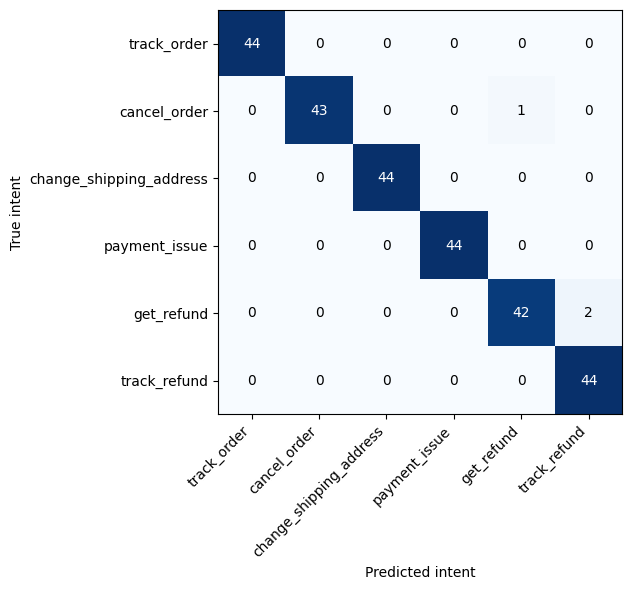

In [59]:
display(pd.read_csv(EVAL / "manually_checked_failures.csv"))
display(pd.read_csv(EVAL / "error_analysis.csv"))
selected = json.loads((EVAL / "validation_selection.json").read_text())["serving_model"]
predictions = pd.read_csv(EVAL / f"{selected}_predictions.csv")
display(
    predictions.loc[
        predictions.y_true != predictions.y_pred,
        ["text", "lang", "y_true", "y_pred", "confidence"],
    ]
)
cm = confusion_matrix(predictions.y_true, predictions.y_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS)), LABELS, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS)), LABELS)
ax.set_xlabel("Predicted intent")
ax.set_ylabel("True intent")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
plt.tight_layout()
plt.show()


**Findings:** The selected classifier made three errors on the 264-message test set. Additional behavioral checks also exposed confusion between requesting and tracking a refund, and a duplicate-payment message classified as cancellation. Aggregate accuracy therefore does not guarantee correct handling of every phrasing.

#### Step 10: Build Policy and Case Retrieval

The assistant retrieves similar historical messages and relevant policy sections using multilingual embeddings. Policy retrieval is evaluated using dense search, hybrid search, and query expansion. The draft quotes the retrieved policy directly, preserving its rules and conditions.

In [60]:
"Classify -> retrieve cases/policy -> draft a cited reply; no live order access."

import gc, json, re, time

from pathlib import Path

import joblib, numpy as np

ART = ROOT / "artifacts"

AR_LABELS = {
    "track_order": "تتبّع الطلب",
    "cancel_order": "إلغاء الطلب",
    "change_shipping_address": "تعديل عنوان الشحن",
    "payment_issue": "مشكلة دفع",
    "get_refund": "طلب استرداد",
    "track_refund": "تتبّع الاسترداد",
}


def normalize_search(s):
    s = re.sub("[\\u064b-\\u0652\\u0670]", "", s).replace("ـ", "")
    return re.sub("[أإآ]", "ا", s).replace("ى", "ي").lower()


def words(s):
    return re.findall("\\w+", normalize_search(s))


def sections():
    out = []
    for path in sorted((ROOT / "data/kb").glob("*.md")):
        title = path.read_text().splitlines()[0].lstrip("# ")
        for i, part in enumerate(re.split("^## ", path.read_text(), flags=re.M)[1:]):
            heading, _, body = part.partition("\n")
            if body.strip():
                out.append(
                    {
                        "id": f"{path.stem}-{i}",
                        "source": f"data/kb/{path.name}",
                        "heading": heading,
                        "text": body.strip(),
                        "lang": "ar" if path.stem == "arabic" else "en",
                        "index_text": title + " > " + heading + "\n" + body.strip(),
                    }
                )
    return out


def reciprocal_rank_fusion(*rankings):
    scores = {}
    for ranking in rankings:
        for rank, idx in enumerate(ranking, 1):
            scores[idx] = scores.get(idx, 0) + 1 / (60 + rank)
    return sorted(scores, key=scores.get, reverse=True)


def policy_excerpt(context, lang, number=1):
    """A transparent extractive draft, not an LLM-written answer."""
    c = context[number - 1]
    intro = "بحسب سياسة Basket:" if lang == "ar" else "According to Basket policy:"
    return {
        "reply": intro + "\n\n" + c["text"],
        "citations": [number],
        "evidence_quote": c["text"],
        "needs_human": False,
        "draft_method": "extractive policy draft",
        "requires_agent_review": True,
    }


def capability_limit(text, lang):
    """Conservative pattern checks, not a trained out-of-scope detector."""
    t = normalize_search(text)
    live = [
        "\\b(gps|live location|exact current.*location)\\b",
        "الموقع (المباشر|الحالي|الفعلي)",
        "وين.*(المندوب|السائق).*الحين",
    ]
    action = [
        "\\b(execute|process|issue)\\b.*\\b(refund|cancellation)\\b.*\\b(now|right now)\\b",
        "^(please )?cancel my order (now|right now)",
        "^(نفذ|نفذي|الغ|الغي|حول|حولي|ارجع|رجع).*?(الان|الحين|لحسابي)",
    ]
    if any((re.search(p, t) for p in live)):
        return "live_data_unavailable"
    if any((re.search(p, t) for p in action)):
        return "account_action_unavailable"
    return None


def expand_policy_query(text):
    """Transparent lexical query expansion; classifier outputs are unchanged."""
    t = normalize_search(text)
    if re.search("الغ|كنسل", t) and (not re.search("رسوم|تكلف", t)):
        return "كيف ألغي الطلب قبل الشحن وبعد الشحن؟"
    if re.search("\\bcancel", t):
        return text + " cancellation before after shipment"
    if re.search("استرداد|استرجاع|refund", t) and re.search(
        "ما وصلت|ما وصل|ما رجع|تعدت|معتمد|تم الاسترداد|approved|issued|credited", t
    ):
        return (
            text + " متابعة استرداد سابق لم يصل البنك tracking existing refund status bank"
        )
    return text


def scope_limit(text):
    """Known unsupported topics; this finite guard is not universal OOD detection."""
    t = normalize_search(text)
    patterns = [
        "\\b(weather|temperature|forecast|job|jobs|career|vacanc\\w*|password|iphone price)\\b",
        "طقس|حراره الجو|وظيف|وظايف|وظائف|توظيف|كلمه (المرور|السر)|رمز الدخول",
        "(كم سعر|بكم|سعر ايفون|اسعار المنتجات)",
        "\\b(price|cost)\\b.*\\b(iphone|laptop|product)\\b",
    ]
    return "outside_supported_intents" if any((re.search(p, t) for p in patterns)) else None


In [61]:
class Assistant:

    def __init__(self):
        from sentence_transformers import SentenceTransformer
        from rank_bm25 import BM25Okapi

        self.embedder = SentenceTransformer(
            CONFIG["embedding_model"],
            revision=CONFIG.get("model_revisions", {}).get("embedding_model"),
            device="cpu",
        )

        meta_path = ART / "encoder_meta.json"
        meta = (
            json.loads(meta_path.read_text())
            if meta_path.exists()
            else {"serving_model": "e5_bilingual"}
        )

        self.name = meta["serving_model"]

        if self.name == "encoder_finetuned":
            from transformers import (
                AutoTokenizer,
                AutoModelForSequenceClassification,
            )

            self.clf = AutoModelForSequenceClassification.from_pretrained(
                ART / "encoder"
            ).eval()
            self.clf_tok = AutoTokenizer.from_pretrained(ART / "encoder")
            self.maxlen = meta["max_length"]
            self.tau = meta["tau"]
        else:
            self.clf = joblib.load(ART / f"{self.name}.joblib")
            self.tau = json.loads(
                (ART / "e5_meta.json").read_text()
            )[self.name]["tau"]

        self.history = load("history").reset_index(drop=True)
        self.H = self.encode(self.history.text.tolist(), "passage: ")

        self.kb = sections()
        self.K = self.encode(
            [section["index_text"] for section in self.kb],
            "passage: ",
        )

        self.bm25 = BM25Okapi(
            [words(section["index_text"]) for section in self.kb]
        )

    def encode(self, texts, prefix="query: "):
        return self.embedder.encode(
            [prefix + text for text in texts],
            normalize_embeddings=True,
            batch_size=64,
            show_progress_bar=False,
        )

    def classify(self, text, q=None):
        if self.name == "encoder_finetuned":
            import torch

            enc = self.clf_tok(
                text,
                return_tensors="pt",
                truncation=True,
                max_length=self.maxlen,
            )

            with torch.inference_mode():
                probabilities = torch.softmax(
                    self.clf(**enc).logits,
                    dim=-1,
                )[0].numpy()

            index = int(probabilities.argmax())
            return (
                self.clf.config.id2label[index],
                float(probabilities[index]),
            )

        features = (
            q.reshape(1, -1)
            if q is not None
            else self.encode([text])
        )
        probabilities = self.clf.predict_proba(features)[0]

        return (
            self.clf.classes_[probabilities.argmax()],
            float(probabilities.max()),
        )

    def retrieve(self, text, q=None, mode="expanded", k=3):
        if mode == "expanded":
            expanded = expand_policy_query(text)
            q = (
                self.encode([expanded])[0]
                if expanded != text or q is None
                else q
            )
        else:
            q = self.encode([text])[0] if q is None else q

        dense = np.argsort(-(self.K @ q)).tolist()
        scores = self.bm25.get_scores(words(text))
        sparse = [
            int(index)
            for index in np.argsort(-scores)
            if scores[index] > 0
        ]

        order = (
            dense
            if mode in {"dense", "expanded"}
            else reciprocal_rank_fusion(dense[:12], sparse[:12])
        )

        lang = "ar" if re.search(r"[\u0600-\u06ff]", text) else "en"
        same_language = [
            index
            for index in order
            if self.kb[index]["lang"] == lang
        ]
        selected = (
            same_language if len(same_language) >= k else order
        )[:k]

        return [
            {
                **self.kb[index],
                "cosine": float(self.K[index] @ q),
            }
            for index in selected
        ]

    @staticmethod
    def fallback(lang, reason):
        reply = (
            "أحتاج مراجعة موظف الدعم لتأكيد الإجابة. "
            "لا أستطيع التحقق من حالة طلبك أو تنفيذ إجراءات على حسابك."
            if lang == "ar"
            else (
                "A support agent needs to review this request. "
                "I cannot check live order status or make changes "
                "to your account."
            )
        )

        return {
            "reply": reply,
            "citations": [],
            "evidence_quote": "",
            "needs_human": True,
            "reason": reason,
            "draft_method": "human-review fallback",
        }

    def __call__(self, text):
        start = time.perf_counter()
        text = str(text).strip()
        lang = "ar" if re.search(r"[\u0600-\u06ff]", text) else "en"

        if not text or len(text) > 4000:
            return {
                **self.fallback(lang, "empty_or_long_input"),
                "intent": None,
                "similar_cases": [],
                "sources": [],
            }

        q = self.encode([text])[0]
        intent, confidence = self.classify(text, q)

        indices = np.argsort(-(self.H @ q))[:3]
        cases = [
            {
                "ticket_id": self.history.iloc[index].ticket_id,
                "text": self.history.iloc[index].text,
                "intent": self.history.iloc[index].intent,
                "response": str(self.history.iloc[index].response),
                "score": round(float(self.H[index] @ q), 3),
            }
            for index in indices
        ]

        context = self.retrieve(text, q)
        capability = capability_limit(text, lang) or scope_limit(text)

        if capability:
            reply = self.fallback(lang, capability)
        elif confidence < self.tau:
            reply = self.fallback(lang, "low_classifier_confidence")
        elif not context or context[0]["cosine"] < 0.65:
            reply = self.fallback(lang, "weak_policy_match")
        else:
            reply = policy_excerpt(context, lang)

        return {
            "intent": intent,
            "intent_ar": AR_LABELS[intent],
            "confidence": round(confidence, 4),
            "threshold": self.tau,
            "classifier": self.name,
            "language": lang,
            **reply,
            "route": (
                "human_review"
                if reply["needs_human"]
                else "draft_for_agent"
            ),
            "similar_cases": cases,
            "sources": [
                {
                    "number": number,
                    "id": section["id"],
                    "source": section["source"],
                    "heading": section["heading"],
                    "text": section["text"],
                }
                for number, section in enumerate(context, 1)
            ],
            "latency_ms": round(
                (time.perf_counter() - start) * 1000,
                1,
            ),
        }


assistant = Assistant()
print("Serving classifier:", assistant.name)
print("Policy sections:", len(assistant.kb))
print("Historical cases:", len(assistant.history))

Serving classifier: e5_bilingual
Policy sections: 29
Historical cases: 1800


#### Step 11: Evaluate Retrieval and Replies

The evaluation measures policy retrieval, similar-case retrieval, draft coverage, review routing, and response latency. The policy questions were used during development to check the assistant’s behavior after changes. Reply correctness and completeness require manual review in addition to checking policy citations.

In [62]:
"Retrieval, answerability, sample outputs, robustness and warm end-to-end latency."

EVAL = ROOT / "evaluation"

POLICY_QUESTIONS = [
    ("Where can I see the courier tracking link?", "en", "orders-2", True),
    (
        "My shipped order has no tracking update yet. How long can it take?",
        "en",
        "orders-2",
        True,
    ),
    ("How do I cancel an order before shipment?", "en", "cancellations-0", True),
    ("Can a shipped order still be cancelled?", "en", "cancellations-0", True),
    ("Can I change the delivery address after shipping?", "en", "shipping-3", True),
    (
        "How do I edit the address of an order that has not shipped?",
        "en",
        "shipping-3",
        True,
    ),
    (
        "My card payment failed but my balance was reduced. What happens?",
        "en",
        "payments-1",
        True,
    ),
    (
        "Both duplicate charges are completed after five business days. What should I do?",
        "en",
        "payments-2",
        True,
    ),
    ("How do I submit a new refund request?", "en", "refunds-1", True),
    ("Where do I get the return label after requesting a refund?", "en", "refunds-1", True),
    ("Where do I track the status of an existing refund?", "en", "refunds-3", True),
    ("How long does a card refund take after it is issued?", "en", "refunds-2", True),
    ("وين ألقى رابط شركة الشحن لمتابعة طلبي؟", "ar", "arabic-0", True),
    ("كم يحتاج التتبع عشان يظهر بعد ما ينشحن الطلب؟", "ar", "arabic-0", True),
    ("كيف ألغي الطلب قبل يشحن؟", "ar", "arabic-1", True),
    ("هل ينفع ألغي طلبي إذا انشحن؟", "ar", "arabic-1", True),
    ("أقدر أغير عنوان التوصيل بعد شحن الطلب؟", "ar", "arabic-2", True),
    ("وين أعدل عنوان الطلب قبل الشحن؟", "ar", "arabic-2", True),
    ("فشل الدفع لكن انخصمت الفلوس متى ينفك الحجز؟", "ar", "arabic-3", True),
    ("الخصم المكرر مكتمل من أكثر من خمسة أيام وش الحل؟", "ar", "arabic-4", True),
    ("كيف أقدم طلب استرجاع مبلغ جديد؟", "ar", "arabic-6", True),
    ("متى يجيني ملصق الإرجاع بعد تقديم الاسترداد؟", "ar", "arabic-6", True),
    ("كيف أتابع حالة استرداد قدمته قبل؟", "ar", "arabic-8", True),
    ("كم يوم يحتاج استرداد بطاقة مدى بعد إصداره؟", "ar", "arabic-7", True),
    ("What is the exact current GPS location of order A-12345?", "en", "", False),
    ("Please execute a refund of 500 SAR into my bank account right now.", "en", "", False),
    ("اعطني الموقع المباشر لمندوب طلبي الحين", "ar", "", False),
    ("نفذ استرداد 500 ريال لحسابي الآن", "ar", "", False),
]


def evaluate():
    EVAL.mkdir(exist_ok=True)
    bot = Assistant()
    questions = pd.DataFrame(
        POLICY_QUESTIONS, columns=["question", "lang", "gold_section", "answerable"]
    )
    questions.to_csv(ROOT / "data/policy_eval.csv", index=False)
    rows = []
    for mode in ["dense", "hybrid", "expanded"]:
        for q in POLICY_QUESTIONS:
            text, lang, gold, answerable = q
            if not answerable:
                continue
            found = bot.retrieve(text, mode=mode, k=5)
            ids = [x["id"] for x in found]
            rank = ids.index(gold) + 1 if gold in ids else None
            rows.append(
                {
                    "method": mode,
                    "lang": lang,
                    "question": text,
                    "gold_section": gold,
                    "rank": rank,
                    "hit_at_1": int(rank == 1),
                    "hit_at_3": int(rank is not None and rank <= 3),
                    "mrr_at_5": 1 / rank if rank else 0,
                }
            )
    rf = pd.DataFrame(rows)
    rf.to_csv(EVAL / "policy_retrieval_predictions.csv", index=False)
    rf.groupby(["method", "lang"])[["hit_at_1", "hit_at_3", "mrr_at_5"]].mean().to_csv(
        EVAL / "policy_retrieval_metrics.csv"
    )
    test = load("test")
    case_rows = []
    for _, r in test.iterrows():
        q = bot.encode([r.text])[0]
        idx = np.argsort(-(bot.H @ q))[:5]
        relevant = bot.history.iloc[idx].intent.to_numpy() == r.intent
        where = np.flatnonzero(relevant)
        case_rows.append(
            {
                "ticket_id": r.ticket_id,
                "lang": r.lang,
                "hit_at_5": int(relevant.any()),
                "mrr_at_5": 1 / (int(where[0]) + 1) if len(where) else 0,
            }
        )
    cases = pd.DataFrame(case_rows)
    cases.to_csv(EVAL / "case_retrieval_predictions.csv", index=False)
    cases.groupby("lang")[["hit_at_5", "mrr_at_5"]].mean().to_csv(
        EVAL / "case_retrieval_metrics.csv"
    )
    results = []
    for text, lang, gold, answerable in POLICY_QUESTIONS:
        out = bot(text)
        cited = [x["id"] for x in out["sources"] if x["number"] in out["citations"]]
        results.append(
            {
                "question": text,
                "lang": lang,
                "answerable": answerable,
                "gold_section": gold,
                "needs_human": out["needs_human"],
                "cites_gold_section": bool(gold and gold in cited),
                "latency_ms": out.get("latency_ms", 0),
                "output": out,
            }
        )
    (EVAL / "sample_inputs_outputs.json").write_text(
        json.dumps(results, ensure_ascii=False, indent=2)
    )
    review = pd.DataFrame(
        [
            {
                "question": r["question"],
                "language": r["lang"],
                "reply": r["output"]["reply"],
                "gold_section": r["gold_section"],
                "cites_gold_section": r["cites_gold_section"],
                "needs_human": r["needs_human"],
                "relevance_correct": "",
                "answer_complete": "",
                "failure_category": "",
                "reviewer_notes": "",
            }
            for r in results
        ]
    )
    review.to_csv(EVAL / "reply_manual_review.csv", index=False)
    summaries = []
    for lang in ["en", "ar"]:
        part = [r for r in results if r["lang"] == lang]
        ans = [r for r in part if r["answerable"]]
        unans = [r for r in part if not r["answerable"]]
        summaries.append(
            {
                "lang": lang,
                "n": len(part),
                "answerable_draft_coverage": np.mean([not r["needs_human"] for r in ans]),
                "gold_section_citation_rate": np.mean(
                    [r["cites_gold_section"] for r in ans]
                ),
                "unanswerable_human_review_rate": np.mean(
                    [r["needs_human"] for r in unans]
                ),
                "note": "Development suite inspected during debugging. Extractive policy drafts; citation matching does not prove relevance or answer completeness.",
            }
        )
    pd.DataFrame(summaries).to_csv(EVAL / "reply_metrics.csv", index=False)
    times = [r["latency_ms"] for r in results[1:]]
    (EVAL / "latency.json").write_text(
        json.dumps(
            {
                "measurement": "warm end-to-end; first request excluded",
                "n": len(times),
                "p50_ms": float(np.percentile(times, 50)),
                "p95_ms": float(np.percentile(times, 95)),
                "reply_mode": "extractive policy draft",
                "api_cost": 0,
                "compute_cost": "Local compute not priced.",
            },
            indent=2,
        )
    )
    tests = [
        ("cancel_en", "I want to cancel my order", "cancel_order"),
        ("cancel_ar", "أريد إلغاء طلبي", "cancel_order"),
        (
            "refund_status",
            "My refund was approved but the money has not arrived",
            "track_refund",
        ),
        ("new_refund", "I want to request a refund", "get_refund"),
        ("payment", "I was charged twice for one order", "payment_issue"),
    ]
    rows = []
    for name, text, expected in tests:
        pred, confidence = bot.classify(text)
        rows.append(
            {
                "name": name,
                "input": text,
                "expected": expected,
                "predicted": pred,
                "passed": pred == expected,
                "confidence": confidence,
            }
        )
    pd.DataFrame(rows).to_csv(EVAL / "behavioral_tests.csv", index=False)
    print("Pipeline evaluation saved:", EVAL)
    return bot


assistant = evaluate()
for filename in [
    "policy_retrieval_metrics.csv",
    "case_retrieval_metrics.csv",
    "reply_metrics.csv",
    "behavioral_tests.csv",
]:
    print(filename)
    display(pd.read_csv(EVAL / filename))
print((EVAL / "latency.json").read_text())


Pipeline evaluation saved: /content/bilingual-support-ticket-assistant/evaluation
policy_retrieval_metrics.csv


,method,lang,hit_at_1,hit_at_3,mrr_at_5
0,dense,ar,1.000000,1.000000,1.000000
1,dense,en,1.000000,1.000000,1.000000
2,expanded,ar,1.000000,1.000000,1.000000
3,expanded,en,1.000000,1.000000,1.000000
4,hybrid,ar,0.833333,0.916667,0.861111
5,hybrid,en,1.000000,1.000000,1.000000


case_retrieval_metrics.csv


,lang,hit_at_5,mrr_at_5
0,ar,0.791667,0.722222
1,en,1.000000,0.997917


reply_metrics.csv


,lang,n,answerable_draft_coverage,gold_section_citation_rate,unanswerable_human_review_rate,note
0,en,14,1.0,1.0,1.0,Development suite inspected during debugging. ...
1,ar,14,1.0,1.0,1.0,Development suite inspected during debugging. ...


behavioral_tests.csv


,name,input,expected,predicted,passed,confidence
0,cancel_en,I want to cancel my order,cancel_order,cancel_order,True,0.987538
1,cancel_ar,أريد إلغاء طلبي,cancel_order,cancel_order,True,0.823624
2,refund_status,My refund was approved but the money has not a...,track_refund,get_refund,False,0.478541
3,new_refund,I want to request a refund,get_refund,get_refund,True,0.854567
4,payment,I was charged twice for one order,payment_issue,cancel_order,False,0.335365


{
  "measurement": "warm end-to-end; first request excluded",
  "n": 27,
  "p50_ms": 47.2,
  "p95_ms": 104.05,
  "reply_mode": "extractive policy draft",
  "api_cost": 0,
  "compute_cost": "Local compute not priced."
}


In [63]:
def evaluate_additional(bot=None):
    bot = bot or Assistant()
    rows = json.loads((ROOT / "data/additional_checks.json").read_text())
    for row in rows:
        out = bot(row["text"])
        cited = [s["id"] for s in out["sources"] if s["number"] in out["citations"]]
        row["output"] = out
        row["passed"] = (
            row["gold"] in cited and (not out["needs_human"])
            if row["answerable"]
            else out["needs_human"]
        )
    (ROOT / "evaluation/additional_checks.json").write_text(
        json.dumps(rows, ensure_ascii=False, indent=2)
    )
    print(
        "Additional synthetic development checks:",
        sum((r["passed"] for r in rows)),
        "/",
        len(rows),
    )
    return rows


additional_checks = evaluate_additional(assistant)
display(
    pd.DataFrame(
        [
            {
                "message": row["text"],
                "answerable": row["answerable"],
                "passed": row["passed"],
            }
            for row in additional_checks
        ]
    )
)


Additional synthetic development checks: 16 / 16


,message,answerable,passed
0,The parcel is already on its way. Is cancellat...,True,True
1,I moved house after dispatch. Can I switch the...,True,True
2,Payment was unsuccessful and the bank shows a ...,True,True
3,Two settled card charges remain a week later. ...,True,True
4,How many hours do I wait for my return shippin...,True,True
5,A refund is marked issued but my bank has not ...,True,True
6,طلبي طلع مع شركة التوصيل، باقي يمديني ألغيه؟,True,True
7,الشحنة بالطريق وأبي أغير عنوانها لمدينة ثانية،...,True,True
8,العملية فشلت والبنك حاط المبلغ معلق، متى يرجع ...,True,True
9,عندي عمليتين خصم مكتملة لنفس الطلب من أسبوع، و...,True,True


**Results:** Dense search and query expansion achieved policy Hit@1 of 1.0000 in both languages on the development questions. Hybrid search achieved Arabic Hit@1 of 0.8333 and English Hit@1 of 1.0000.
Similar-case retrieval achieved Hit@5 of 1.0000 for English and 0.7917 for Arabic. Matching intent is used as a proxy for case relevance.

All 24 answerable policy questions received excerpts citing the expected section, and all 4 live-data/action requests were routed to review. The additional development checks passed 16/16, where success means citing the expected policy or routing an unsupported request to review—not predicting every intent correctly.

The separate classifier behavioral checks passed 3/5. An additional inspection of the 12 answerable development cases found 5 correct intent predictions, using the intent associated with each reference policy as the expected label. These errors show that successful policy retrieval can occur despite an incorrect intent prediction.

Warm response latency was 47.20 ms at p50 and 104.05 ms at p95, excluding the first request.
These inspected development results do not establish real-world answer accuracy or universal detection of unsupported requests.

#### Step 12: Inspect Sample Replies

Sample outputs are inspected by comparing each customer message with its predicted intent, reply, and cited policy. The reply review table can be completed with relevance, completeness, and failure categories.

In [64]:
samples = json.loads((EVAL / "sample_inputs_outputs.json").read_text())
for index in [3, 6, 16, 19, 26]:
    row = samples[index]
    print("Message:", row["question"])
    print("Intent:", row["output"].get("intent"))
    print("Reply:", row["output"]["reply"])
    print("Citations:", row["output"]["citations"])
    print()
display(pd.read_csv(EVAL / "reviewed_pipeline_failures.csv"))
display(pd.read_csv(EVAL / "reply_manual_review.csv"))


Message: Can a shipped order still be cancelled?
Intent: cancel_order
Reply: According to Basket policy:

You can cancel an order free of charge from **My Orders** until it is marked "Shipped". Cancellation is immediate and the payment authorisation is released by your bank, usually within 3 to 5 business days. Orders that are already shipped cannot be cancelled; instead, refuse the delivery or request a return after delivery.
Citations: [1]

Message: My card payment failed but my balance was reduced. What happens?
Intent: payment_issue
Reply: According to Basket policy:

A payment may fail because of insufficient balance, an expired card, a 3-D Secure verification timeout, or a bank limit on online purchases. Your order is kept for 30 minutes so you can retry with the same or another method. If the payment failed but money was deducted, it is an authorisation hold that your bank will release automatically within 3 to 5 business days.
Citations: [1]

Message: أقدر أغير عنوان التوصيل بع

,question,category,observed_failure,diagnosis_limit,run
0,Can a shipped order still be cancelled?,policy_contradiction,Reply allows an action after shipment although...,Original raw model output unavailable for reje...,previous Colab generative pipeline
1,أقدر أغير عنوان التوصيل بعد شحن الطلب؟,policy_contradiction,Reply allows an action after shipment although...,Original raw model output unavailable for reje...,previous Colab generative pipeline
2,My card payment failed but my balance was redu...,incomplete_answer,Reply states retry window but omits bank hold ...,Original raw model output unavailable for reje...,previous Colab generative pipeline
3,Both duplicate charges are completed after fiv...,unsupported_action_claim,We will process refund implies action; policy ...,Original raw model output unavailable for reje...,previous Colab generative pipeline
4,Where can I see the courier tracking link?,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline
5,How do I cancel an order before shipment?,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline
6,Can I change the delivery address after shipping?,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline
7,How do I submit a new refund request?,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline
8,وين ألقى رابط شركة الشحن لمتابعة طلبي؟,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline
9,فشل الدفع لكن انخصمت الفلوس متى ينفك الحجز؟,unnecessary_human_review,Answerable policy question returned invalid_ge...,Original raw model output unavailable for reje...,previous Colab generative pipeline


,question,language,reply,gold_section,cites_gold_section,needs_human,relevance_correct,answer_complete,failure_category,reviewer_notes
0,Where can I see the courier tracking link?,en,According to Basket policy:\n\nOpen **My Order...,orders-2,True,False,NaN,NaN,NaN,NaN
1,My shipped order has no tracking update yet. H...,en,According to Basket policy:\n\nOpen **My Order...,orders-2,True,False,NaN,NaN,NaN,NaN
2,How do I cancel an order before shipment?,en,According to Basket policy:\n\nYou can cancel ...,cancellations-0,True,False,NaN,NaN,NaN,NaN
3,Can a shipped order still be cancelled?,en,According to Basket policy:\n\nYou can cancel ...,cancellations-0,True,False,NaN,NaN,NaN,NaN
4,Can I change the delivery address after shipping?,en,According to Basket policy:\n\nThe delivery ad...,shipping-3,True,False,NaN,NaN,NaN,NaN
5,How do I edit the address of an order that has...,en,According to Basket policy:\n\nThe delivery ad...,shipping-3,True,False,NaN,NaN,NaN,NaN
6,My card payment failed but my balance was redu...,en,According to Basket policy:\n\nA payment may f...,payments-1,True,False,NaN,NaN,NaN,NaN
7,Both duplicate charges are completed after fiv...,en,According to Basket policy:\n\nIf you see two ...,payments-2,True,False,NaN,NaN,NaN,NaN
8,How do I submit a new refund request?,en,According to Basket policy:\n\nOpen **My Order...,refunds-1,True,False,NaN,NaN,NaN,NaN
9,Where do I get the return label after requesti...,en,According to Basket policy:\n\nOpen **My Order...,refunds-1,True,False,NaN,NaN,NaN,NaN


**Findings:** Earlier failures included unnecessary escalation, contradictions of shipping conditions, incomplete answers, and unsupported action claims. The revised default uses verbatim policy excerpts to avoid changing those conditions. It can still retrieve an irrelevant section, so agent review remains necessary.

The manual-review fields are currently blank. Citation checks have passed, but relevance and completeness have not yet been scored through human review.

#### Step 13: Launch the Gradio Demo

The bilingual interface displays the predicted intent, classifier confidence, policy draft, evidence, and similar messages. The assistant provides guidance; it cannot access customer accounts or perform transactions.

In [65]:
import gradio as gr
from html import escape

"Bilingual agent workspace. Run after training: python app.py."

CSS = "\n.gradio-container {max-width:1180px !important; margin:auto; font-family:Arial,sans-serif;}\n#hero {padding:30px 32px; border-radius:20px; background:linear-gradient(120deg,#102c46,#14575a); color:white; margin-bottom:20px;}\n#hero h1 {color:white; font-size:30px; margin:8px 0;}\n#hero p {color:#d7e9ec; max-width:780px; line-height:1.7;}\n.eyebrow {font-size:12px; letter-spacing:2px; color:#9fe0cf; font-weight:700;}\n.panel {border:1px solid #dde5ec; border-radius:16px; padding:20px; background:var(--block-background-fill);}\n#reply textarea, #ticket textarea {unicode-bidi:plaintext; line-height:1.9; font-size:16px;}\n#analyze {min-height:48px; border-radius:10px;}\n.summary {display:flex; flex-wrap:wrap; gap:12px; margin:0 0 15px;}\n.metric {flex:1; min-width:140px; border:1px solid #dae5ea; border-radius:12px; padding:14px;}\n.metric small {display:block; color:#607482; margin-bottom:8px;}\n.metric strong {font-size:17px; color:#155e63;}\n.case {border:1px solid #dde5ec; border-radius:12px; padding:15px; margin:10px 0;}\n.case p {unicode-bidi:plaintext; line-height:1.8; margin:8px 0;}\n.source {border-left:3px solid #259b92; padding:12px 18px; margin:12px 0; background:var(--block-background-fill);}\n.source p {unicode-bidi:plaintext; line-height:1.9;}\n.footnote {font-size:12px; color:#657884; line-height:1.7;}\n"


def present(out):
    """Escape all input/model text before placing it into HTML."""
    intent = escape(out.get("intent_ar", "") + " / " + str(out.get("intent") or "—"))
    route = (
        "مراجعة موظف / Human review" if out["needs_human"] else "مسودة سياسة / Policy draft"
    )
    summary = (
        '<div class="summary">'
        + "".join(
            (
                f'<div class="metric"><small>{label}</small><strong>{value}</strong></div>'
                for label, value in [
                    ("التصنيف · Intent", intent),
                    ("ثقة التصنيف · Confidence", f"{out.get('confidence', 0):.1%}"),
                    ("المسار · Route", route),
                ]
            )
        )
        + "</div>"
    )
    case_html = (
        "".join(
            (
                f"""<div class="case"><small>{escape(c['intent'])} · Similarity {c['score']:.3f}</small><p dir="auto">{escape(c['text'])}</p></div>"""
                for c in out["similar_cases"]
            )
        )
        or "<p>No similar cases.</p>"
    )
    source_html = (
        "".join(
            (
                f"""<div class="source"><strong>[{c['number']}] {escape(c['heading'])}</strong><p dir="auto">{escape(c['text'])}</p><small>{escape(c['source'])}</small></div>"""
                for c in out["sources"]
            )
        )
        or "<p>No policy evidence.</p>"
    )
    reply = out["reply"]
    if out["citations"]:
        reply += "\n\n" + " ".join((f"[{c}]" for c in out["citations"]))
    reasons = {
        "live_data_unavailable": "يتطلب بيانات مباشرة غير متاحة · Live account data is unavailable",
        "account_action_unavailable": "يتطلب تنفيذ إجراء بواسطة موظف · An agent must perform this action",
        "outside_supported_intents": "خارج مواضيع الدعم الستة · Outside the six supported topics",
        "low_classifier_confidence": "تصنيف الرسالة غير مؤكد · Intent needs confirmation",
        "weak_policy_match": "لم نجد سياسة مطابقة بما يكفي · No sufficiently relevant policy",
        "empty_or_long_input": "أدخل رسالة من 1 إلى 4000 حرف · Enter 1–4000 characters",
    }
    status = (
        reasons.get(out.get("reason"), "تحتاج الرسالة مراجعة موظف · Agent review needed")
        if out["needs_human"]
        else "مقتطف من السياسة للمراجعة قبل الإرسال · Policy excerpt: review before sending"
    )
    return (summary, reply, status, case_html, source_html, out)


def build_app(assistant=None):
    assistant = assistant or Assistant()

    def run(text):
        return present(assistant(text))

    with gr.Blocks(
        title="Basket | Support Workspace",
        theme=gr.themes.Soft(primary_hue="teal", secondary_hue="slate"),
        css=CSS,
    ) as demo:
        gr.HTML(
            '<div id="hero"><span class="eyebrow">BASKET · SUPPORT WORKSPACE</span><h1>مساعد خدمة العملاء</h1><p>Arabic & English ticket understanding, similar cases, and policy evidence — in one workspace.<br>حلّل رسالة العميل وراجع مسودة الرد ومصادرها.</p></div>'
        )
        with gr.Row(equal_height=False):
            with gr.Column(scale=4, min_width=300, elem_classes="panel"):
                gr.Markdown("### رسالة العميل · Customer message")
                ticket = gr.Textbox(
                    label="اكتب الرسالة بالعربي أو الإنجليزي",
                    placeholder="مثال: أقدر ألغي طلبي بعد ما انشحن؟",
                    lines=5,
                    max_lines=10,
                    elem_id="ticket",
                )
                button = gr.Button(
                    "تحليل الرسالة · Analyze ticket", variant="primary", elem_id="analyze"
                )
                gr.Examples(
                    examples=[
                        ["كيف ألغي الطلب قبل يشحن؟"],
                        ["انخصم المبلغ مرتين لنفس الطلب"],
                        ["كيف أتابع حالة استرداد قدمته؟"],
                        ["Can I change my delivery address after shipping?"],
                    ],
                    inputs=ticket,
                    label="جرّب مثالًا · Try an example",
                )
                gr.HTML(
                    '<p class="footnote">Basket متجر افتراضي. المساعد يعرض إرشادات عامة ولا يدخل حساب العميل أو ينفذ معاملات.<br>Classification confidence measures the intent prediction, not reply correctness.</p>'
                )
            with gr.Column(scale=7, min_width=360, elem_classes="panel"):
                summary = gr.HTML(
                    "<p>النتائج تظهر هنا بعد التحليل · Analyze a message to see results.</p>"
                )
                reply = gr.Textbox(
                    label="مسودة الرد · Evidence-based draft",
                    lines=7,
                    interactive=False,
                    elem_id="reply",
                )
                status = gr.Textbox(
                    label="ملاحظة المراجعة · Review note", interactive=False
                )
                with gr.Tabs():
                    with gr.Tab("السياسات · Policy evidence"):
                        sources = gr.HTML()
                    with gr.Tab("حالات مشابهة · Similar cases"):
                        gr.Markdown(
                            "Retrieved historical messages; their original responses are not policy authority."
                        )
                        cases = gr.HTML()
                with gr.Accordion("تفاصيل تقنية · Technical details", open=False):
                    raw = gr.JSON()
        outputs = [summary, reply, status, cases, sources, raw]
        button.click(run, inputs=ticket, outputs=outputs, concurrency_limit=1)
        ticket.submit(run, inputs=ticket, outputs=outputs, concurrency_limit=1)
    return demo


demo = build_app(assistant)
demo.queue().launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://36d0b50884a0dfe5d8.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


#### Step 14: Save the Experiment
Runtime details are saved, and the project is exported with its measured results and sample outputs. Download the executed notebook separately through **File → Download → Download .ipynb** to keep its cell outputs.

In [66]:
import platform
import importlib.metadata
import zipfile

runtime = {
    "python": platform.python_version(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "seed": CONFIG["seed"],
    "packages": {
        name: importlib.metadata.version(name)
        for name in [
            "torch",
            "transformers",
            "sentence-transformers",
            "scikit-learn",
            "pandas",
            "gradio",
        ]
    },
    "reply_mode": "extractive policy draft",
}
(EVAL / "basket_runtime.json").write_text(json.dumps(runtime, indent=2))
export = ROOT.parent / "Basket_Support_Assistant_Results.zip"
excluded = {".git", ".gradio", "__pycache__", ".pytest_cache", "checkpoints", "colab_run"}
with zipfile.ZipFile(export, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(ROOT.rglob("*")):
        if not path.is_file() or excluded.intersection(path.relative_to(ROOT).parts):
            continue
        if (
            path.suffix in {".bin", ".safetensors", ".pem", ".pyc"}
            or path.name == "bitext_raw.csv"
        ):
            continue
        archive.write(path, Path("support-ticket-assistant") / path.relative_to(ROOT))
print("Saved:", export.name)
if "google.colab" in sys.modules:
    from google.colab import files

    files.download(str(export))


Saved: Basket_Support_Assistant_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### Conclusion

Multilingual embeddings with bilingual classifier training performed strongly in the recorded experiment. Encoder fine-tuning provided a useful comparison but did not improve on the selected classifier. Policy retrieval and extractive drafts addressed the observed reply contradictions while keeping evidence visible.

The remaining limitations are the small Arabic test, synthetic Arabic training data, templated English messages, imperfect intent classification, and development-only reply checks. Broader independently authored evaluation would be needed to support stronger generalization claims.